# 03 - SLA breach model

The modeling phase, told from its saved results. The plan was fixed before training in the decision record at the end of [notebook 02](02_feature_assessment.ipynb) and in `src/opspilot/modeling/config.py`.

This notebook only **reads** files in `reports/modeling/`, produced by the modeling commands (see the README). It does not fit or score any model, so it cannot reuse the test set. To regenerate the inputs:

```
python -m opspilot.modeling.compare            # validation comparison
python -m opspilot.modeling.operating_point    # threshold and calibration
python -m opspilot.modeling.train              # one-time test evaluation
python -m opspilot.modeling.explain            # feature importance and examples
```

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from opspilot.modeling.compare import summarize
from opspilot.modeling.evaluation import select_model

ROOT = Path.cwd().parent
RESULTS = ROOT / "reports" / "modeling"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titlelocation": "left", "axes.titleweight": "bold",
})
ACCENT, MUTED, HIGHLIGHT = "#2f6690", "#9aa5b1", "#d1495b"


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")


cv = pd.read_csv(RESULTS / "cv_results.csv")
operating_point = json.loads((RESULTS / "operating_point.json").read_text())
test = json.loads((RESULTS / "test_results.json").read_text())

## 1. Comparison on the validation folds

In [2]:
summary = summarize(cv)
columns = ["average_precision_mean", "average_precision_std", "roc_auc_mean", "brier_mean",
           "precision_at_capacity_mean", "recall_at_capacity_mean"]
print(f"selected by the pre-registered rule: {select_model(summary)}")
summary[columns].round(3)

selected by the pre-registered rule: xgboost


,average_precision_mean,average_precision_std,roc_auc_mean,brier_mean,precision_at_capacity_mean,recall_at_capacity_mean
model,,,,,,
xgboost,0.672,0.008,0.894,0.084,0.711,0.448
random_forest,0.657,0.002,0.888,0.086,0.699,0.440
logistic_regression_interactions,0.652,0.008,0.884,0.087,0.699,0.441
logistic_regression,0.640,0.010,0.881,0.088,0.686,0.432
baseline_subcategory_history,0.310,0.005,0.738,0.120,0.379,0.239
baseline_prior,0.159,0.005,0.500,0.134,0.160,0.101


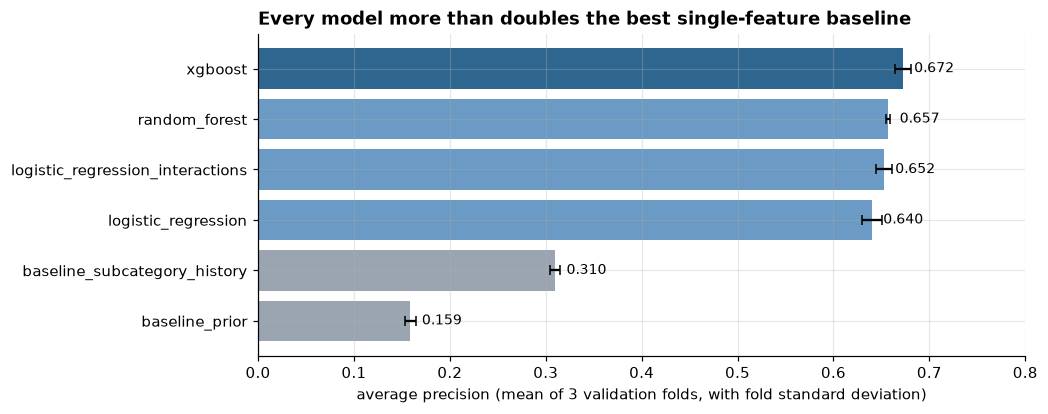

In [3]:
order = summary.index[::-1]
colors = [ACCENT if name == select_model(summary) else (MUTED if name.startswith("baseline") else "#6b9ac4")
          for name in order]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(order, summary.loc[order, "average_precision_mean"], xerr=summary.loc[order, "average_precision_std"],
        color=colors, capsize=3)
for y, value in enumerate(summary.loc[order, "average_precision_mean"]):
    ax.text(value + 0.012, y, f"{value:.3f}", va="center", fontsize=9)
ax.set_xlabel("average precision (mean of 3 validation folds, with fold standard deviation)")
ax.set_xlim(0, 0.8)
ax.set_title("Every model more than doubles the best single-feature baseline")
save(fig, "03_model_comparison")

In [4]:
# Paired view: the same three validation quarters for every model.
by_fold = cv.pivot(index="fold", columns="model", values="average_precision")
by_fold[["xgboost", "random_forest", "logistic_regression_interactions", "logistic_regression"]].round(3)

model,xgboost,random_forest,logistic_regression_interactions,logistic_regression
fold,,,,
1,0.674,0.655,0.652,0.638
2,0.663,0.657,0.644,0.631
3,0.679,0.659,0.661,0.651


All four models score between 0.640 and 0.672 average precision, more than double the best single-feature baseline (0.310) and about four times the no-information baseline (0.159). The spread between folds is small (about 0.01), so differences of 0.02 are meaningful.

The pre-registered rule selects XGBoost: its mean is 0.020 above the logistic regression with interactions and 0.015 above the random forest, both beyond the 0.01 tolerance. The paired table shows it is ahead in every fold.

The operational difference is smaller than the metric difference suggests. At the 10% review capacity, XGBoost reaches 71.1% precision and 44.8% recall against 69.9% and 44.1% for the logistic regression with interactions.

In [5]:
# Best setting in each model family's grid.
grids = {"logistic regression": "cv_logreg_grid.csv", "random forest": "cv_rf_grid.csv", "XGBoost": "cv_xgb_grid.csv"}
best = []
for family, file in grids.items():
    grid = summarize(pd.read_csv(RESULTS / file))
    best.append({"family": family, "settings_tried": len(grid), "best_setting": grid.index[0],
                 "best_ap": grid["average_precision_mean"].iloc[0], "worst_ap": grid["average_precision_mean"].iloc[-1]})
pd.DataFrame(best).round(3)

,family,settings_tried,best_setting,best_ap,worst_ap
0,logistic regression,8,logreg_C=1.0_weight=none,0.642,0.620
1,random forest,6,rf_leaf=20_features=0.5,0.657,0.639
2,XGBoost,8,xgb_depth=3_lr=0.05_trees=500,0.672,0.645


Each family was tuned on a small fixed grid. In both tree families the more regularized settings did best (depth 3 for XGBoost, leaves of at least 20 tickets for the random forest), which fits data with a lot of random variation.

The logistic regression grid's best setting is C = 1.0 (0.642), but the model uses C = 0.1 (0.640). Settings within 0.01 of the best were treated as equivalent and the most regularized was chosen, the same simpler-is-better rule used between families.

## 2. Operating threshold and calibration

threshold for 10% review capacity: 0.457
share flagged in each validation quarter at that threshold: {'1': '9.3%', '2': '11.7%', '3': '8.6%'}
for comparison, best-F1 threshold 0.287 flags 18.7% (precision 55.2%, recall 64.9%)


,review_share,threshold,precision,recall
0,0.05,0.687,0.878,0.276
1,0.10,0.457,0.708,0.445
2,0.15,0.342,0.599,0.565
3,0.20,0.271,0.531,0.667
4,0.30,0.182,0.426,0.804


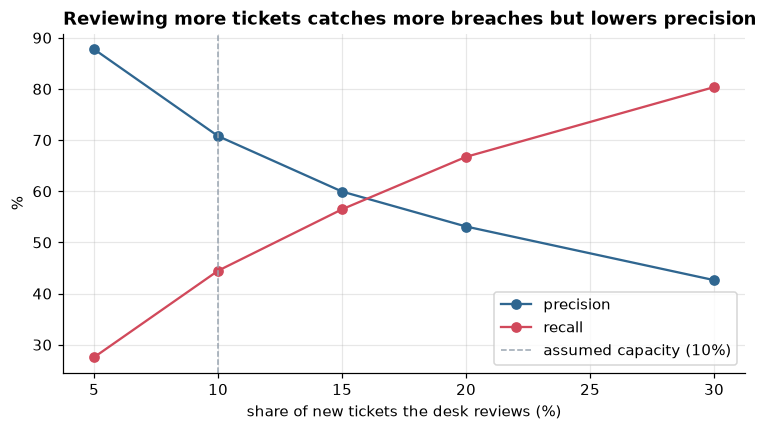

In [6]:
print(f"threshold for {operating_point['review_capacity']:.0%} review capacity: {operating_point['threshold']:.3f}")
print("share flagged in each validation quarter at that threshold:",
      {k: f"{v:.1%}" for k, v in operating_point["share_flagged_by_fold"].items()})
best_f1 = operating_point["best_f1"]
print(f"for comparison, best-F1 threshold {best_f1['threshold']:.3f} flags {best_f1['share_flagged']:.1%} "
      f"(precision {best_f1['precision']:.1%}, recall {best_f1['recall']:.1%})")

capacity = pd.read_csv(RESULTS / "capacity_curve_validation.csv")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(100 * capacity["review_share"], 100 * capacity["precision"], marker="o", color=ACCENT, label="precision")
ax.plot(100 * capacity["review_share"], 100 * capacity["recall"], marker="o", color=HIGHLIGHT, label="recall")
ax.axvline(100 * operating_point["review_capacity"], color=MUTED, ls="--", lw=1, label="assumed capacity (10%)")
ax.set_xlabel("share of new tickets the desk reviews (%)")
ax.set_ylabel("%")
ax.set_title("Reviewing more tickets catches more breaches but lowers precision")
ax.legend()
save(fig, "03_capacity_curve")
capacity.round(3)

The operating threshold is the predicted risk that flags 10% of validation tickets: 0.457. With a fixed threshold the share flagged follows the risk in each period (8.6% to 11.7% across the validation quarters), so the desk's review load would vary by a few percentage points.

The capacity curve shows the trade-off the operations team would choose along: reviewing 5% of tickets gives 88% precision but catches 28% of breaches; reviewing 20% catches 67% at 53% precision. The F1-optimal threshold (0.287, flagging 18.7%) is shown for comparison but not used, because F1 assumes a missed breach and an unnecessary review cost the same, which has not been established.

expected calibration error: validation 0.0037, test 0.0051


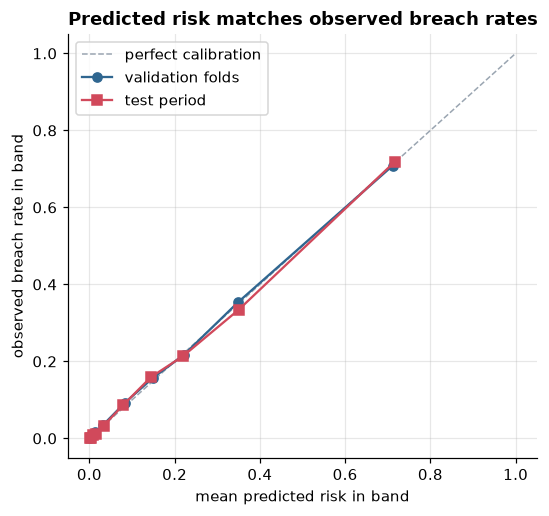

In [7]:
validation_bands = pd.read_csv(RESULTS / "calibration_validation.csv")
test_bands = pd.read_csv(RESULTS / "test_calibration.csv")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1, label="perfect calibration")
ax.plot(validation_bands["mean_predicted"], validation_bands["observed_rate"], marker="o", color=ACCENT, label="validation folds")
ax.plot(test_bands["mean_predicted"], test_bands["observed_rate"], marker="s", color=HIGHLIGHT, label="test period")
ax.set_xlabel("mean predicted risk in band")
ax.set_ylabel("observed breach rate in band")
ax.set_title("Predicted risk matches observed breach rates")
ax.legend()
save(fig, "03_calibration")
print(f"expected calibration error: validation {operating_point['calibration']['expected_calibration_error']:.4f}, "
      f"test {test['selected']['expected_calibration_error']:.4f}")

In every risk band the mean prediction is close to the observed breach rate, on validation and on test (expected calibration error 0.0037 and 0.0051). A ticket shown as "35% risk" breaches about 35% of the time. No calibration step was added: a time-respecting isotonic calibration tested on the validation folds did not improve calibration and lowered average precision, because it had to hold back training data.

## 3. The one-time test evaluation

In [8]:
selected = test["selected"]
rows = []
for metric in ["average_precision", "roc_auc", "brier"]:
    low, high = selected["intervals_95"][metric]
    rows.append({"metric": metric, "test": selected[metric], "low_95": low, "high_95": high,
                 "validation_mean": summary.loc[test["model"], f"{metric}_mean"]})
at = selected["at_threshold"]
for metric in ["precision", "recall"]:
    low, high = selected["intervals_95"][f"{metric}_at_threshold"]
    rows.append({"metric": f"{metric} at threshold", "test": at[metric], "low_95": low, "high_95": high,
                 "validation_mean": summary.loc[test["model"], f"{metric}_at_capacity_mean"]})
print(f"{test['model']} scored once on {test['test_tickets']:,} tickets ({test['test_period'][0][:10]} to "
      f"{test['test_period'][1][:10]}) from commit {test['git']['commit'][:7]}; "
      f"uncommitted changes: {test['git']['uncommitted_changes']}")
print(f"share flagged: {at['share_flagged']:.1%}; caught {at['true_positives']:,}, false alarms {at['false_positives']:,}, "
      f"missed {at['false_negatives']:,}")
pd.DataFrame(rows).round(3)

xgboost scored once on 11,747 tickets (2025-07-01 to 2025-12-17) from commit e6d8fe5; uncommitted changes: False
share flagged: 10.1%; caught 848, false alarms 341, missed 995


,metric,test,low_95,high_95,validation_mean
0,average_precision,0.680,0.661,0.699,0.672
1,roc_auc,0.897,0.890,0.904,0.894
2,brier,0.082,0.078,0.085,0.084
3,precision at threshold,0.713,0.687,0.738,0.711
4,recall at threshold,0.460,0.436,0.482,0.448


In [9]:
references = pd.DataFrame(test["references"]).T[["average_precision", "roc_auc", "brier"]]
references.loc[test["model"]] = [selected["average_precision"], selected["roc_auc"], selected["brier"]]
references.sort_values("average_precision", ascending=False).round(3)

,average_precision,roc_auc,brier
xgboost,0.680,0.897,0.082
logistic_regression_interactions,0.666,0.892,0.084
baseline_subcategory_history,0.313,0.745,0.119
baseline_prior,0.157,0.500,0.132


The test period was scored once, from a committed version of the code. Every metric is consistent with validation: average precision 0.680 (95% interval 0.661 to 0.699) against 0.672 on validation, ROC-AUC 0.897, Brier 0.082. There is no sign that model or threshold choices overfitted the validation folds.

At the threshold the model flagged 10.1% of test tickets. 848 of the 1,189 flagged tickets breached (71.3% precision), and the model reached 46.0% of all breaches. The remaining 995 breaches were not flagged; many breaches look ordinary when the ticket is created and go wrong later, which a creation-time model cannot see.

On the same test period the logistic regression with interactions scores 0.666, 0.014 below XGBoost. The validation choice holds, but a team that valued a fully inspectable model would give up little by using it.

,n,base_rate,average_precision,roc_auc,share_flagged,precision_at_threshold,recall_at_threshold
group,,,,,,,
Network Operations,1681,0.261,0.706,0.847,0.159,0.746,0.457
Enterprise Applications,1958,0.231,0.671,0.838,0.151,0.692,0.451
Desktop Support,2209,0.187,0.691,0.884,0.139,0.692,0.516
Security Operations,614,0.168,0.693,0.858,0.076,0.936,0.427
Classroom Technology,683,0.165,0.712,0.863,0.092,0.841,0.469
Identity & Access,1918,0.125,0.632,0.887,0.083,0.654,0.435
Service Desk,2684,0.032,0.569,0.963,0.018,0.612,0.353


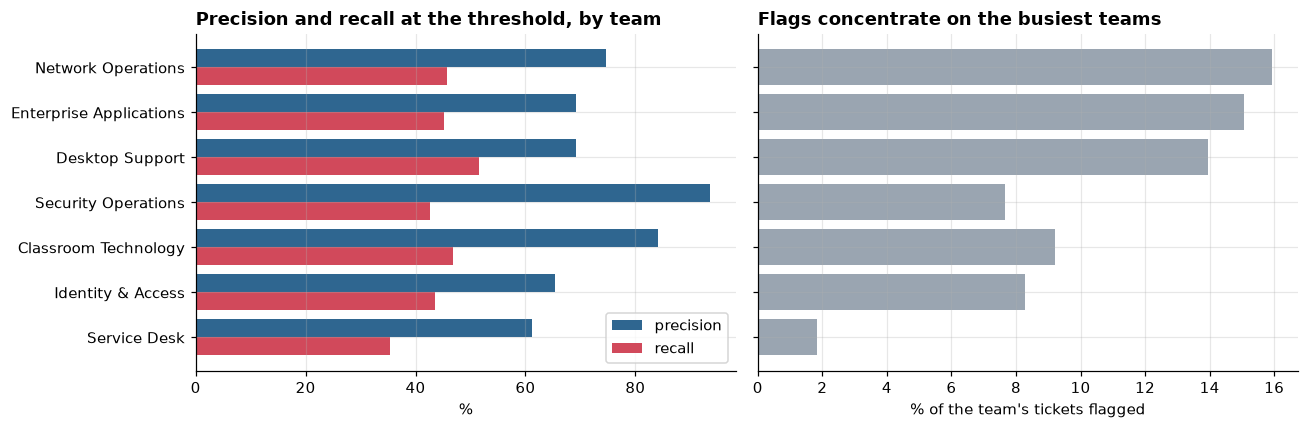

In [10]:
by_team = pd.read_csv(RESULTS / "test_by_team.csv").set_index("group").sort_values("base_rate", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
y = np.arange(len(by_team))
axes[0].barh(y - 0.2, 100 * by_team["precision_at_threshold"], height=0.4, color=ACCENT, label="precision")
axes[0].barh(y + 0.2, 100 * by_team["recall_at_threshold"], height=0.4, color=HIGHLIGHT, label="recall")
axes[0].set_yticks(y, by_team.index)
axes[0].invert_yaxis()
axes[0].set_xlabel("%")
axes[0].set_title("Precision and recall at the threshold, by team")
axes[0].legend(loc="lower right")
axes[1].barh(y, 100 * by_team["share_flagged"], color=MUTED)
axes[1].set_xlabel("% of the team's tickets flagged")
axes[1].set_title("Flags concentrate on the busiest teams")
fig.tight_layout()
save(fig, "03_test_by_team")
by_team.drop(columns="small_group").round(3)

In [11]:
pd.read_csv(RESULTS / "test_by_month.csv").set_index("group").drop(columns="small_group").round(3)

,n,base_rate,average_precision,roc_auc,share_flagged,precision_at_threshold,recall_at_threshold
group,,,,,,,
2025-07,1414,0.117,0.652,0.912,0.065,0.739,0.412
2025-08,2015,0.154,0.666,0.893,0.112,0.680,0.494
2025-09,2485,0.157,0.661,0.889,0.109,0.672,0.466
2025-10,2467,0.167,0.678,0.897,0.103,0.701,0.432
2025-11,2028,0.171,0.726,0.903,0.106,0.786,0.487
2025-12,1338,0.163,0.692,0.890,0.099,0.742,0.450


**By team:** no team is badly served. ROC-AUC ranges from 0.84 to 0.96 and recall from 35% to 52%. Flags concentrate where breaches are common: Network Operations, Enterprise Applications and Desktop Support have 14-16% of their tickets flagged, Service Desk 1.8%. Service Desk has the lowest average precision (0.569) despite the highest ROC-AUC (0.963), because only 3.2% of its tickets breach and average precision depends heavily on the base rate.

**By month:** average precision stays between 0.65 and 0.73. July has the fewest flags (6.5%) because its base rate is lowest (11.7%); the other months flag 10-11%.

## 4. What the model relies on

,feature,mean_abs_shap,ap_drop_mean,ap_drop_std
0,subcategory_breach_rate_prev_90d,0.8544,0.1230,0.0046
1,sla_hours,0.7504,0.1321,0.0026
2,priority,0.6268,0.1619,0.0055
3,hours_until_staffed,0.4253,0.2187,0.0053
4,team_open_per_agent,0.3466,0.0495,0.0040
5,subcategory,0.2393,0.0164,0.0023
6,subcategory_resolved_prev_90d,0.1761,0.0039,0.0015
7,assigned_team,0.0986,0.0077,0.0013
8,day_of_week,0.0744,0.0048,0.0013
9,hour_of_day,0.0682,0.0043,0.0013


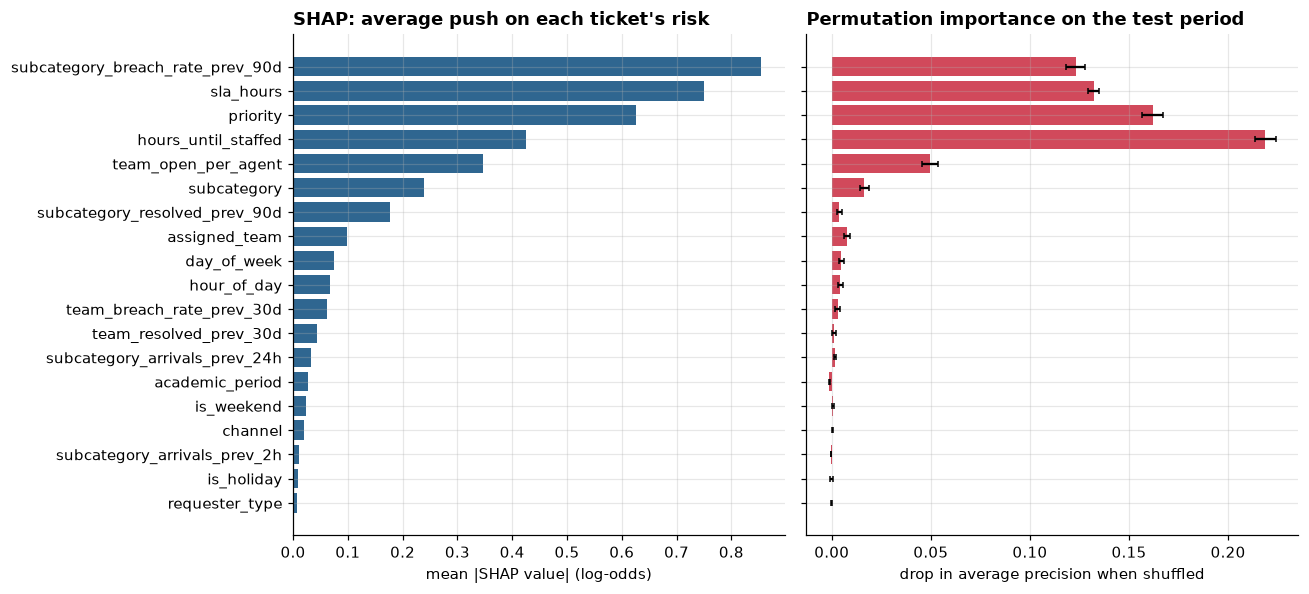

In [12]:
importance = pd.read_csv(RESULTS / "feature_importance.csv")
ordered = importance.sort_values("mean_abs_shap")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
axes[0].barh(ordered["feature"], ordered["mean_abs_shap"], color=ACCENT)
axes[0].set_xlabel("mean |SHAP value| (log-odds)")
axes[0].set_title("SHAP: average push on each ticket's risk")
axes[1].barh(ordered["feature"], ordered["ap_drop_mean"], xerr=ordered["ap_drop_std"], color=HIGHLIGHT, capsize=2)
axes[1].set_xlabel("drop in average precision when shuffled")
axes[1].set_title("Permutation importance on the test period")
fig.tight_layout()
save(fig, "03_feature_importance")
importance.round(4)

In [13]:
examples = json.loads((RESULTS / "example_explanations.json").read_text())
for case, ticket in examples["examples"].items():
    reasons = "; ".join(f"{r['feature']}={r['value']} ({r['contribution']:+.2f})" for r in ticket["reasons"])
    print(f"{case}: {ticket['ticket_id']} risk {ticket['predicted_risk']:.1%}, breached={ticket['breached']}\n    {reasons}")

caught_breach: TKT-041779 risk 99.7%, breached=True
    hours_until_staffed=13.24 (+2.32); priority=P2 (+1.40); sla_hours=8.0 (+1.18); subcategory_breach_rate_prev_90d=0.4167 (+0.98)
false_alarm: TKT-040733 risk 94.8%, breached=False
    hours_until_staffed=13.74 (+2.06); team_open_per_agent=6.17 (+0.85); sla_hours=24.0 (+0.65); subcategory_breach_rate_prev_90d=0.314 (+0.48)
missed_breach: TKT-045425 risk 0.1%, breached=True
    subcategory_breach_rate_prev_90d=0.0058 (-3.05); sla_hours=72.0 (-1.10); subcategory_resolved_prev_90d=686.0 (-0.81); subcategory=password_reset (-0.22)


Both methods agree on the five features that matter: the issue type's recent breach rate, the SLA target, priority, hours until the desk opens, and team workload. That is what the exploratory analysis predicted.

They rank them differently because correlated features share credit. Shuffling `hours_until_staffed` costs the most average precision because nothing else carries that information. SHAP gives the most credit to `subcategory_breach_rate_prev_90d`, which the trees use in place of many one-hot subcategory columns. Neither method measures cause.

Academic period, channel, requester type, holidays and short-term arrival counts contribute almost nothing and are candidates to drop when the model is next retrained.

The three examples show what per-ticket reasons look like: an evening P2 ticket flagged at 99.7% that did breach; a ticket that arrived overnight to a busy team, flagged at 94.8%, that was resolved in time; and a password reset given 0.1% risk that breached anyway because of something that happened after creation.

## Summary

| | |
|---|---|
| Selected model | XGBoost (depth 3, learning rate 0.05, 500 trees), chosen by a rule fixed before tree models were scored |
| Validation | Average precision 0.672, against 0.310 for the best single-feature baseline |
| Test (scored once) | Average precision 0.680 (0.661-0.699), ROC-AUC 0.897, Brier 0.082 |
| Operating point | Risk >= 0.457; flagged 10.1% of test tickets, 71% precision, 46% recall |
| Calibration | Predicted risk matches observed rates (ECE 0.005); no calibration step needed |
| Simpler alternative | Logistic regression with interactions: 0.666 on test, little practical difference |
| Main drivers | Issue type history, SLA target, priority, hours until opening, team workload |

The model card ([docs/model_card.md](../docs/model_card.md)) covers intended use, limitations and what the model must not be used for.